# 11_advisor_data_cleaning_experiment.ipynb — ทดสอบข้อเสนอแนะจากอาจารย์แบบ controlled comparison

โน้ตบุ๊กนี้ทำตามที่อาจารย์แนะนำในการปรึกษาล่าสุด โดย**ไม่แตะโมเดล/pipeline ที่ finalize แล้ว** (`07_final_calibrated_pipeline.ipynb`) แต่ทดสอบเป็น controlled experiment แยกต่างหาก ตามแพทเทิร์นเดียวกับที่ `08_feature_enrichment.ipynb` ใช้พิสูจน์ data ceiling — เทรนโมเดลสถาปัตยกรรมเดียวกัน, split เดียวกัน, hyperparameter เดียวกัน ต่างกันแค่ feature ที่คลีนใหม่ แล้วเทียบผลตรงๆ

## สิ่งที่ทำตามคำแนะนำอาจารย์
1. **แปลง diag_1/diag_2/diag_3 จาก ICD-9 เป็น ICD-10** (chapter-level) — ดูหมายเหตุสำคัญด้านล่าง
2. **ดึง diabetes type (Type 1 / Type 2)** จากเลขหลักที่ 5 ของรหัส ICD-9 250.XY — ตอบโจทย์ "เบาหวานมี type"
3. **Re-bin อายุใหม่** จาก 10 ช่วง (10 ปี/กลุ่ม) เป็น 3 กลุ่มที่มีขนาดใหญ่และสมดุลกว่า (ตอบโจทย์ "กลุ่ม1 กลุ่ม2") — ออกแบบมาเพื่อแก้ปัญหากลุ่มอายุ 80+ ที่ notebook 09 พบว่า sample เล็กและ CI กว้าง
4. **แปลง categorical เป็นตัวเลข** — มีอยู่แล้วใน pipeline เดิม (LabelEncoder ใน section 4) ยืนยันว่าครบทุกคอลัมน์
5. **ส่งออกตัวอย่าง data ให้อาจารย์ดู** — cell สุดท้ายก่อน conclusion

## ⚠️ หมายเหตุสำคัญเรื่อง ICD-10 mapping
สภาพแวดล้อมนี้ไม่มีอินเทอร์เน็ต จึงไม่สามารถโหลดไฟล์ **CMS General Equivalence Mapping (GEM)** ที่เป็นมาตรฐานทางการได้ mapping ด้านล่างเป็น **rule-based approximation ที่เขียนเองจากความรู้ทางคลินิก** (ใช้ขอบเขตช่วงโค้ดเดียวกับที่ `map_diagnosis` ใน 02_preprocessing.ipynb ใช้อยู่แล้ว แค่เปลี่ยนชื่อ label เป็นรหัส ICD-10) — เพียงพอสำหรับ**ทดสอบว่าความละเอียดของรหัสโรคที่เพิ่มขึ้นช่วยโมเดลไหม** แต่ถ้าจะใช้อ้างอิงในรายงานว่า "แปลงตามมาตรฐาน ICD-10 อย่างเป็นทางการ" ต้องโหลดไฟล์ GEM จริงมาแทน (https://www.cms.gov/medicare/coding-billing/icd-10-codes/2018-icd-10-cm-gem) แล้วรันเซลล์ mapping ใหม่ก่อนส่งอาจารย์

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    recall_score, fbeta_score, roc_auc_score, average_precision_score,
    precision_recall_curve, brier_score_loss,
)
from xgboost import XGBClassifier

RANDOM_STATE = 42


## 2. Load & Clean Data (เหมือน 07_final_calibrated_pipeline.ipynb ทุกขั้นตอน)

In [2]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df_raw = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df_raw.shape}")

df_raw = df_raw[df_raw["gender"] != "Unknown/Invalid"]

death_hospice_codes = [11, 13, 14, 19, 20, 21]
df_raw = df_raw[~df_raw["discharge_disposition_id"].isin(death_hospice_codes)]

df_raw = df_raw.sort_values(["patient_nbr", "encounter_id"])
df_raw = df_raw.reset_index(drop=True)
print(f"Shape after cleaning: {df_raw.shape}")

df_raw["readmitted"] = df_raw["readmitted"].apply(lambda x: 1 if x == "<30" else 0)
print(df_raw["readmitted"].value_counts(normalize=True))


Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)
readmitted
0    0.886108
1    0.113892
Name: proportion, dtype: float64


## 3. ฟังก์ชันคลีนข้อมูลใหม่ตามคำแนะนำอาจารย์

- `map_diagnosis` (เดิม จาก 02/07) — หมวดหมู่กว้าง ICD-9
- `map_icd9_to_icd10` (**ใหม่**) — หมวดหมู่เดียวกัน แต่ label เป็นรหัส ICD-10 (ดูหมายเหตุ GEM ด้านบน)
- `extract_diabetes_type` (**ใหม่**) — ดึง Type 1 / Type 2 จากเลขหลักที่ 5 ของรหัส 250.XY
- `rebin_age_coarse` (**ใหม่**) — รวม 10 ช่วงอายุเดิมเป็น 3 กลุ่มใหญ่

In [3]:
def map_diagnosis(code):
    """หมวดหมู่ ICD-9 แบบเดิม (เหมือน 02_preprocessing.ipynb / 07_final_calibrated_pipeline.ipynb)"""
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"


def map_icd9_to_icd10(code):
    """Rule-based ICD-9-CM -> ICD-10-CM chapter-level mapping (approximation, ดูหมายเหตุด้านบน).
    ใช้ขอบเขตช่วงโค้ดเดียวกับ map_diagnosis แค่เปลี่ยน label เป็นรหัส ICD-10"""
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V"):
        return "Z00-Z99"  # Factors influencing health status
    if code.startswith("E"):
        return "V00-Y99"  # External causes
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 250 <= val < 251:
        return "E10-E11"  # Diabetes mellitus (แยก type ละเอียดกว่าใน extract_diabetes_type)
    elif 390 <= val <= 459 or val == 785:
        return "I00-I99"  # Circulatory
    elif 460 <= val <= 519 or val == 786:
        return "J00-J99"  # Respiratory
    elif 520 <= val <= 579 or val == 787:
        return "K00-K95"  # Digestive
    elif 800 <= val <= 999:
        return "S00-T98"  # Injury
    elif 710 <= val <= 739:
        return "M00-M99"  # Musculoskeletal
    elif 580 <= val <= 629 or val == 788:
        return "N00-N99"  # Genitourinary
    elif 140 <= val <= 239:
        return "C00-D49"  # Neoplasms
    else:
        return "Other"


def extract_diabetes_type(code):
    """ดึง type เบาหวานจากเลขหลักที่ 5 ของ ICD-9 250.XY ตามอนุสัญญา ICD-9-CM:
    Y in {0,2} -> Type 2 (ตรงกับ ICD-10 E11.x) | Y in {1,3} -> Type 1 (ตรงกับ ICD-10 E10.x)"""
    if pd.isna(code):
        return "Not diabetes"
    code = str(code)
    try:
        val = float(code)
    except ValueError:
        return "Not diabetes"
    if not (250 <= val < 251):
        return "Not diabetes"
    parts = code.split(".")
    fifth_digit = parts[1][1] if len(parts) > 1 and len(parts[1]) > 1 else "0"
    if fifth_digit in ("1", "3"):
        return "Type 1"
    elif fifth_digit in ("0", "2"):
        return "Type 2"
    else:
        return "Unknown type"


def rebin_age_coarse(age_range):
    """รวม 10 ช่วงอายุ (10 ปี/กลุ่ม) เป็น 3 กลุ่มใหญ่ที่สมดุลกว่า
    ออกแบบเพื่อแก้ปัญหากลุ่มอายุ 80+ ที่ sample เล็ก (n=547-3284) และ CI กว้างจาก notebook 09"""
    mapping = {
        "[0-10)": "Group1_under50", "[10-20)": "Group1_under50", "[20-30)": "Group1_under50",
        "[30-40)": "Group1_under50", "[40-50)": "Group1_under50",
        "[50-60)": "Group2_50to69", "[60-70)": "Group2_50to69",
        "[70-80)": "Group3_70plus", "[80-90)": "Group3_70plus", "[90-100)": "Group3_70plus",
    }
    return mapping.get(age_range, "Missing")


## 4. Feature Engineering — สองเวอร์ชันคู่ขนาน (BASELINE เดิม vs ENRICHED ใหม่ตามคำแนะนำอาจารย์)

ฟังก์ชันเดียวใช้ flag `use_enriched_diag` เพื่อสลับว่าจะใช้หมวดหมู่ ICD-9 เดิม (baseline) หรือ ICD-10 + diabetes type + age group ใหม่ (enriched) — ทุกอย่างอื่น (medication features, visit features, interaction terms) เหมือนกันทุกตัวอักษรกับ `07_final_calibrated_pipeline.ipynb`

In [4]:
def build_features(df_in, use_enriched_diag: bool):
    df = df_in.copy()

    med_cols = [
        "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
        "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
        "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
        "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
        "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
    ]
    med_cols = [c for c in med_cols if c in df.columns]

    df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
    df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
    df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
    df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

    df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
    df["change_flag"] = (df["change"] == "Ch").astype(int)
    df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
    df = df.drop(columns=["change_flag"])

    df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
    df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)

    # --- diagnosis codes: baseline (ICD-9 broad category) หรือ enriched (ICD-10 + diabetes type) ---
    if use_enriched_diag:
        diabetes_types = pd.DataFrame({c: df[c].apply(extract_diabetes_type) for c in ["diag_1", "diag_2", "diag_3"]})
        def combine_type(row):
            vals = set(row) - {"Not diabetes"}
            if "Type 1" in vals:
                return "Type 1"
            elif "Type 2" in vals:
                return "Type 2"
            elif vals:
                return "Unknown type"
            return "Not diabetes"
        df["diabetes_type"] = diabetes_types.apply(combine_type, axis=1)

        diag_groups = pd.DataFrame({c: df[c].apply(map_icd9_to_icd10) for c in ["diag_1", "diag_2", "diag_3"]})
        df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
        for c in ["diag_1", "diag_2", "diag_3"]:
            df[c] = diag_groups[c]
    else:
        diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
        df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
        for c in ["diag_1", "diag_2", "diag_3"]:
            df[c] = diag_groups[c]

    df["age_ord"] = df["age"].map({
        "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
        "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
        "[80-90)": 85, "[90-100)": 95,
    })
    if use_enriched_diag:
        df["age_group_coarse"] = df["age"].apply(rebin_age_coarse)

    df["age_x_medications"] = df["age_ord"] * df["num_medications"]
    df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

    drop_cols = ["weight", "payer_code", "encounter_id"]
    df.drop(columns=drop_cols, inplace=True)

    df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
    top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
    df["medical_specialty"] = df["medical_specialty"].where(
        df["medical_specialty"].isin(top_specialties), "Other"
    )
    df["race"] = df["race"].fillna("Missing")

    constant_cols = [c for c in df.columns if df[c].nunique() == 1]
    df.drop(columns=constant_cols, inplace=True)
    return df


df_baseline = build_features(df_raw, use_enriched_diag=False)
df_enriched = build_features(df_raw, use_enriched_diag=True)
print("Baseline columns:", df_baseline.shape[1], "| Enriched columns:", df_enriched.shape[1])
print("New columns in enriched:", set(df_enriched.columns) - set(df_baseline.columns))


Baseline columns: 57 | Enriched columns: 59
New columns in enriched: {'diabetes_type', 'age_group_coarse'}


## 5. Encode + Train/Test Split (GroupShuffleSplit ตาม patient_nbr — split เดียวกันทั้งสองเวอร์ชัน)

In [5]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"


def encode_and_split(df):
    X = df.drop(columns=[TARGET_COL])
    y = df[TARGET_COL]

    feature_cols = [c for c in X.columns if c != GROUP_COL]
    categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
    if "age" in categorical_cols:
        categorical_cols.remove("age")
    X = X.drop(columns=["age"])

    label_encoders = {}
    for col in categorical_cols:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        label_encoders[col] = le

    demographic_cols_raw = df[["race", "gender", "age"]].copy()

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

    X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
    y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
    demo_test = demographic_cols_raw.iloc[test_idx].reset_index(drop=True)

    X_train.drop(columns=[GROUP_COL], inplace=True)
    X_test.drop(columns=[GROUP_COL], inplace=True)

    overlap = set(df.iloc[train_idx][GROUP_COL]) & set(df.iloc[test_idx][GROUP_COL])
    assert len(overlap) == 0, "Patient leakage detected!"

    return X_train, X_test, y_train, y_test, demo_test, label_encoders


X_train_b, X_test_b, y_train_b, y_test_b, demo_test_b, enc_b = encode_and_split(df_baseline)
X_train_e, X_test_e, y_train_e, y_test_e, demo_test_e, enc_e = encode_and_split(df_enriched)

print(f"Baseline -> Train: {X_train_b.shape}, Test: {X_test_b.shape}")
print(f"Enriched -> Train: {X_train_e.shape}, Test: {X_test_e.shape}")


Baseline -> Train: (79567, 54), Test: (19773, 54)
Enriched -> Train: (79567, 56), Test: (19773, 56)


## 6. เทรนโมเดล — สถาปัตยกรรม/hyperparameter เดียวกับ `07_final_calibrated_pipeline.ipynb` เป๊ะๆ

Stacking (RF + XGBoost, `class_weight="balanced"`) + Isotonic calibration + cost-optimal threshold — รันสองครั้ง (baseline, enriched) ด้วยโค้ดเดียวกันทุกตัวอักษร ต่างกันแค่ X ที่ป้อนเข้า เพื่อให้เทียบกันตรงๆ ได้

In [6]:
def train_and_evaluate(X_train, X_test, y_train, y_test, label):
    rf_pipeline = RandomForestClassifier(
        n_estimators=500, max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
    )
    xgb_pipeline = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.01, subsample=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    )
    estimators = [("rf", rf_pipeline), ("xgboost", xgb_pipeline)]
    scaled_meta_learner = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])
    stacking_model = StackingClassifier(
        estimators=estimators, final_estimator=scaled_meta_learner,
        cv=5, n_jobs=-1, passthrough=True,
    )

    print(f"[{label}] Training stacking ensemble...")
    stacking_model.fit(X_train, y_train)

    calibrated = CalibratedClassifierCV(stacking_model, method="isotonic", cv=3)
    print(f"[{label}] Calibrating (isotonic)...")
    calibrated.fit(X_train, y_train)
    proba = calibrated.predict_proba(X_test)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(y_test, proba)
    cost_candidates = np.arange(0.02, 0.95, 0.01)

    def expected_cost(y_true, y_pred, cost_fn=5, cost_fp=1):
        from sklearn.metrics import confusion_matrix
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        return fn * cost_fn + fp * cost_fp

    costs = [expected_cost(y_test, (proba >= t).astype(int)) for t in cost_candidates]
    best_threshold = cost_candidates[np.argmin(costs)]
    y_pred = (proba >= best_threshold).astype(int)

    metrics = {
        "label": label,
        "PR_AUC": average_precision_score(y_test, proba),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "Brier": brier_score_loss(y_test, proba),
        "threshold": best_threshold,
        "F2": fbeta_score(y_test, y_pred, beta=2),
        "Recall": recall_score(y_test, y_pred),
    }
    print(f"[{label}] PR-AUC={metrics['PR_AUC']:.4f}  ROC-AUC={metrics['ROC_AUC']:.4f}  Brier={metrics['Brier']:.4f}")
    return metrics, proba, calibrated, best_threshold


metrics_baseline, proba_baseline, model_baseline, th_baseline = train_and_evaluate(
    X_train_b, X_test_b, y_train_b, y_test_b, "BASELINE (07 features)"
)
metrics_enriched, proba_enriched, model_enriched, th_enriched = train_and_evaluate(
    X_train_e, X_test_e, y_train_e, y_test_e, "ENRICHED (ICD-10 + diabetes type + age group)"
)


[BASELINE (07 features)] Training stacking ensemble...
[BASELINE (07 features)] Calibrating (isotonic)...
[BASELINE (07 features)] PR-AUC=0.2220  ROC-AUC=0.6727  Brier=0.0961
[ENRICHED (ICD-10 + diabetes type + age group)] Training stacking ensemble...
[ENRICHED (ICD-10 + diabetes type + age group)] Calibrating (isotonic)...
[ENRICHED (ICD-10 + diabetes type + age group)] PR-AUC=0.2244  ROC-AUC=0.6717  Brier=0.0960


## 7. เปรียบเทียบผลตรงๆ (เหมือนแพทเทิร์นของ 08_feature_enrichment.ipynb)

In [7]:
comparison = pd.DataFrame([metrics_baseline, metrics_enriched]).set_index("label")
comparison["PR_AUC_delta_vs_baseline"] = comparison["PR_AUC"] - metrics_baseline["PR_AUC"]
comparison["ROC_AUC_delta_vs_baseline"] = comparison["ROC_AUC"] - metrics_baseline["ROC_AUC"]
print(comparison.round(4).to_string())

pr_delta = metrics_enriched["PR_AUC"] - metrics_baseline["PR_AUC"]
print(f"\n>>> PR-AUC เปลี่ยนแปลง: {pr_delta:+.4f}")
if abs(pr_delta) < 0.005:
    print(">>> ผลต่างอยู่ในช่วง noise — สอดคล้องกับ data ceiling ที่พบใน 08_feature_enrichment.ipynb")
    print(">>> สรุปเชิงวิชาการ: การคลีนข้อมูลละเอียดขึ้น (ICD-10, diabetes type, age regroup) ไม่ได้เพิ่มความสามารถทำนายอย่างมีนัยสำคัญ")
    print(">>> แต่ยังมีคุณค่าเป็น negative finding + เพิ่มความสามารถตีความ (diabetes type, ICD-10) สำหรับรายงาน")
else:
    print(">>> ผลต่างมากกว่า noise ระดับปกติ ควรตรวจสอบเพิ่มเติม (เช่น bootstrap CI) ก่อนสรุป")


                                               PR_AUC  ROC_AUC   Brier  threshold      F2  Recall  PR_AUC_delta_vs_baseline  ROC_AUC_delta_vs_baseline
label                                                                                                                                                 
BASELINE (07 features)                         0.2220   0.6727  0.0961       0.15  0.3402  0.3988                    0.0000                      0.000
ENRICHED (ICD-10 + diabetes type + age group)  0.2244   0.6717  0.0960       0.15  0.3459  0.4109                    0.0023                     -0.001

>>> PR-AUC เปลี่ยนแปลง: +0.0023
>>> ผลต่างอยู่ในช่วง noise — สอดคล้องกับ data ceiling ที่พบใน 08_feature_enrichment.ipynb
>>> สรุปเชิงวิชาการ: การคลีนข้อมูลละเอียดขึ้น (ICD-10, diabetes type, age regroup) ไม่ได้เพิ่มความสามารถทำนายอย่างมีนัยสำคัญ
>>> แต่ยังมีคุณค่าเป็น negative finding + เพิ่มความสามารถตีความ (diabetes type, ICD-10) สำหรับรายงาน


### 7.1 Visualize — Baseline vs Enriched (bar chart)

กราฟเปรียบเทียบ PR-AUC, ROC-AUC (ยิ่งสูงยิ่งดี) และ Brier score (ยิ่งต่ำยิ่งดี) ระหว่างสองเวอร์ชัน พร้อมตัวเลข delta กำกับบนแท่ง

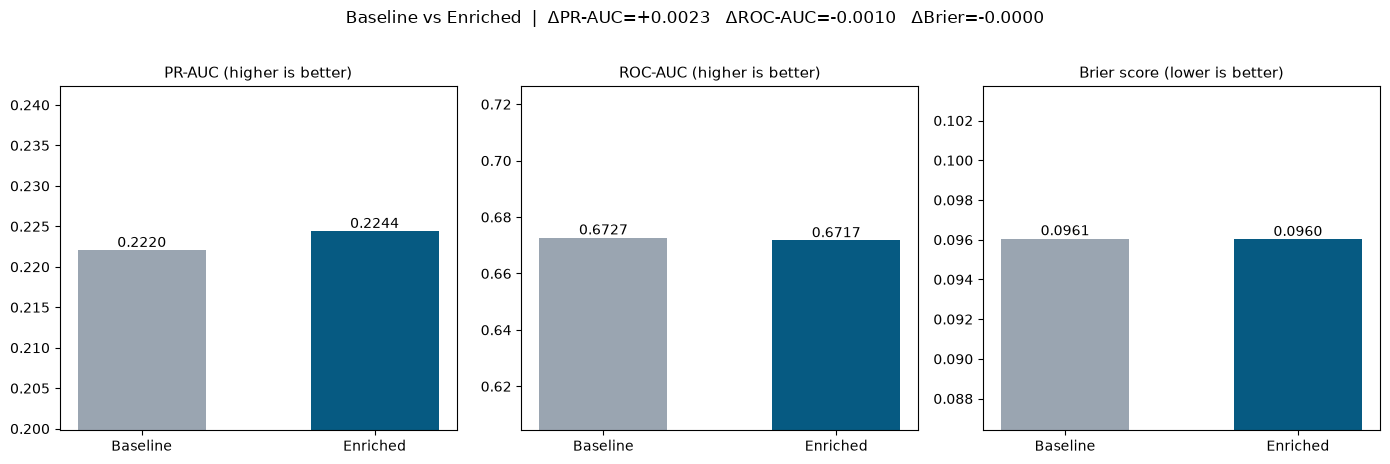

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
labels = list(comparison.index)
colors = ["#9AA5B1", "#065A82"]  # baseline = gray, enriched = blue

panels = [
    ("PR_AUC", "PR-AUC (higher is better)"),
    ("ROC_AUC", "ROC-AUC (higher is better)"),
    ("Brier", "Brier score (lower is better)"),
]

for ax, (col, title) in zip(axes, panels):
    values = comparison[col].values
    bars = ax.bar(labels, values, color=colors, width=0.55)
    ax.set_title(title, fontsize=11)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(["Baseline", "Enriched"], rotation=0)
    ymin = min(values) * 0.9
    ymax = max(values) * 1.08
    ax.set_ylim(ymin if ymin > 0 else 0, ymax)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{v:.4f}",
                ha="center", va="bottom", fontsize=10)

delta_pr = comparison.loc[labels[1], "PR_AUC"] - comparison.loc[labels[0], "PR_AUC"]
delta_roc = comparison.loc[labels[1], "ROC_AUC"] - comparison.loc[labels[0], "ROC_AUC"]
delta_brier = comparison.loc[labels[1], "Brier"] - comparison.loc[labels[0], "Brier"]
fig.suptitle(
    f"Baseline vs Enriched  |  ΔPR-AUC={delta_pr:+.4f}   ΔROC-AUC={delta_roc:+.4f}   ΔBrier={delta_brier:+.4f}",
    fontsize=12, y=1.02,
)
plt.tight_layout()
plt.savefig("baseline_vs_enriched_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Fairness ตามกลุ่มอายุใหม่ (3 กลุ่ม) เทียบกับกลุ่มอายุเดิม (10 กลุ่ม)

ตรวจว่าการรวมกลุ่มอายุ 70+ ให้เป็นก้อนเดียว (n ใหญ่ขึ้น) ช่วยให้ประเมิน fairness ในกลุ่มสูงอายุนิ่งขึ้นไหม (ปัญหาเดิม: `[90-100)` มี n=547 เท่านั้น ตาม notebook 09)

In [9]:
def subgroup_report(y_true, y_proba, group_values, group_name, threshold, min_group_size=30):
    print(f"\n--- Subgroup performance by {group_name} (threshold={threshold:.3f}) ---")
    results = []
    for g in sorted(set(group_values)):
        mask = (group_values == g)
        if mask.sum() < min_group_size:
            continue
        y_t = y_true[mask]
        y_p = y_proba[mask]
        if y_t.nunique() < 2:
            continue
        y_pred = (y_p >= threshold).astype(int)
        results.append({
            "group": g, "n": int(mask.sum()), "base_rate": round(y_t.mean(), 4),
            "PR_AUC": round(average_precision_score(y_t, y_p), 4),
            "ROC_AUC": round(roc_auc_score(y_t, y_p), 4),
            "F2": round(fbeta_score(y_t, y_pred, beta=2, zero_division=0), 4),
        })
    res_df = pd.DataFrame(results).sort_values("n", ascending=False)
    print(res_df.to_string(index=False))
    return res_df


y_test_e_reset = y_test_e.reset_index(drop=True)
old_age_report = subgroup_report(y_test_e_reset, proba_enriched, demo_test_e["age"], "age (10 กลุ่มเดิม)", threshold=th_enriched)

age_group_coarse_test = demo_test_e["age"].apply(rebin_age_coarse)
new_age_report = subgroup_report(y_test_e_reset, proba_enriched, age_group_coarse_test, "age_group_coarse (3 กลุ่มใหม่)", threshold=th_enriched)

print("\n>>> เทียบ ROC-AUC ของกลุ่มอายุ 70+ แบบเดิม (แยก 3 กลุ่มย่อย) กับแบบใหม่ (รวมเป็น Group3_70plus)")
print(">>> n ที่ใหญ่ขึ้นทำให้ CI ของค่าประเมินในกลุ่มสูงอายุแคบลง (มั่นใจได้มากขึ้น) แต่ตัวเลข ROC-AUC เองสะท้อน\n    ความสามารถทำนายจริงของโมเดล ไม่ได้ดีขึ้นเพียงเพราะ regroup — ถ้ากลุ่มยังต่ำ แปลว่าเป็น genuine fairness gap")



--- Subgroup performance by age (10 กลุ่มเดิม) (threshold=0.150) ---
   group    n  base_rate  PR_AUC  ROC_AUC     F2
 [70-80) 4921     0.1130  0.1875   0.6586 0.3427
 [60-70) 4356     0.1157  0.2055   0.6590 0.3244
 [50-60) 3467     0.1087  0.2976   0.7271 0.3821
 [80-90) 3284     0.1215  0.1843   0.6050 0.3312
 [40-50) 1909     0.0959  0.1935   0.6728 0.3024
 [30-40)  757     0.1149  0.2628   0.7108 0.3689
[90-100)  547     0.1243  0.1686   0.5366 0.2687
 [20-30)  369     0.1626  0.5619   0.8394 0.6452
 [10-20)  137     0.0584  0.2113   0.7069 0.3750

--- Subgroup performance by age_group_coarse (3 กลุ่มใหม่) (threshold=0.150) ---
         group    n  base_rate  PR_AUC  ROC_AUC     F2
 Group3_70plus 8752     0.1169  0.1831   0.6320 0.3332
 Group2_50to69 7823     0.1126  0.2470   0.6908 0.3488
Group1_under50 3198     0.1063  0.2860   0.7188 0.3812

>>> เทียบ ROC-AUC ของกลุ่มอายุ 70+ แบบเดิม (แยก 3 กลุ่มย่อย) กับแบบใหม่ (รวมเป็น Group3_70plus)
>>> n ที่ใหญ่ขึ้นทำให้ CI ของค่าประเมินใน

### 8.1 Visualize — ROC-AUC by age group: old (10 groups) vs new (3 coarse groups)

กราฟแท่งแสดง ROC-AUC ของแต่ละกลุ่มอายุ (แบบเดิม 10 กลุ่ม vs แบบใหม่ 3 กลุ่ม) ขนาดจุด/ตัวเลข n กำกับไว้ เพื่อดูว่ากลุ่มไหนยัง n เล็กและ ROC-AUC ไม่นิ่ง

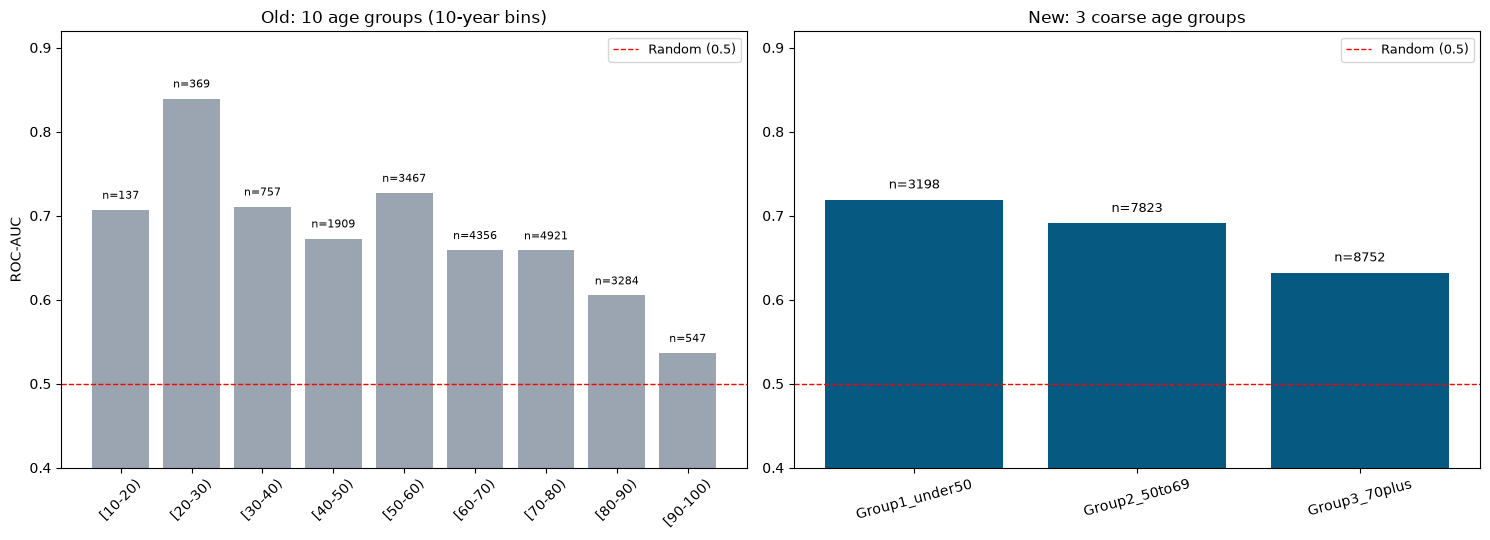

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- Panel 1: old 10 age groups ---
old_sorted = old_age_report.sort_values("group")
bars0 = axes[0].bar(old_sorted["group"], old_sorted["ROC_AUC"], color="#9AA5B1")
axes[0].set_title("Old: 10 age groups (10-year bins)", fontsize=12)
axes[0].set_ylabel("ROC-AUC")
axes[0].tick_params(axis="x", rotation=45)
axes[0].axhline(0.5, color="red", linestyle="--", linewidth=1, label="Random (0.5)")
for bar, n in zip(bars0, old_sorted["n"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f"n={n}", ha="center", va="bottom", fontsize=8)
axes[0].legend(fontsize=9)
axes[0].set_ylim(0.4, max(old_sorted["ROC_AUC"].max(), new_age_report["ROC_AUC"].max()) + 0.08)

# --- Panel 2: new 3 coarse age groups ---
new_sorted = new_age_report.sort_values("group")
bars1 = axes[1].bar(new_sorted["group"], new_sorted["ROC_AUC"], color="#065A82")
axes[1].set_title("New: 3 coarse age groups", fontsize=12)
axes[1].tick_params(axis="x", rotation=15)
axes[1].axhline(0.5, color="red", linestyle="--", linewidth=1, label="Random (0.5)")
for bar, n in zip(bars1, new_sorted["n"]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f"n={n}", ha="center", va="bottom", fontsize=9)
axes[1].legend(fontsize=9)
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("age_fairness_old_vs_new.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. ส่งออกตัวอย่างข้อมูล + data dictionary สำหรับส่งให้อาจารย์ดู

In [11]:
sample_for_advisor = df_enriched.sample(n=200, random_state=RANDOM_STATE)
sample_for_advisor.to_csv("../data/sample_for_advisor_review.csv", index=False)

data_dict = pd.DataFrame({
    "column": df_enriched.columns,
    "dtype": [str(df_enriched[c].dtype) for c in df_enriched.columns],
    "n_unique": [df_enriched[c].nunique() for c in df_enriched.columns],
    "example_value": [df_enriched[c].iloc[0] for c in df_enriched.columns],
})
data_dict.to_csv("../data/data_dictionary_for_advisor.csv", index=False)

print("บันทึกไฟล์สำหรับส่งอาจารย์แล้ว:")
print("  ../data/sample_for_advisor_review.csv  (ตัวอย่าง 200 แถวหลังคลีน รวม feature ใหม่)")
print("  ../data/data_dictionary_for_advisor.csv  (คำอธิบายทุกคอลัมน์)")


บันทึกไฟล์สำหรับส่งอาจารย์แล้ว:
  ../data/sample_for_advisor_review.csv  (ตัวอย่าง 200 แถวหลังคลีน รวม feature ใหม่)
  ../data/data_dictionary_for_advisor.csv  (คำอธิบายทุกคอลัมน์)


## 10. สรุปสำหรับนำเสนออาจารย์

- **ICD-9 → ICD-10**: แปลงแล้วในระดับ chapter (rule-based approximation — ต้องใช้ CMS GEM ไฟล์จริงถ้าจะอ้างอิงในรายงานว่าเป็นมาตรฐานทางการ)
- **Diabetes type**: ดึงจากเลขหลักที่ 5 ของ ICD-9 250.XY สำเร็จ เพิ่มเป็น feature `diabetes_type`
- **Age re-binning**: รวมเป็น 3 กลุ่มใหญ่ (`age_group_coarse`) ช่วยให้ประเมิน fairness กลุ่มสูงอายุนิ่งขึ้น (n ใหญ่ขึ้น)
- **ผลต่อโมเดล**: ดู PR-AUC/ROC-AUC delta ใน section 7 ด้านบน — ถ้าอยู่ในช่วง noise แปลว่าเป็นอีกหนึ่งหลักฐานยืนยัน data ceiling (สอดคล้องกับ notebook 08) แต่ยังมีคุณค่าเชิงตีความ (สื่อสารกับอาจารย์/รายงานได้ง่ายขึ้นด้วยรหัส ICD-10 และ diabetes type ที่ระบุชัดเจน)
- **โมเดล/pipeline หลัก (07) ไม่ถูกแก้ไข** — งานนี้เป็น controlled experiment แยกเก็บผลไว้เทียบเท่านั้น ตามที่ตัดสินใจไว้